# 06 — Classification: Predicting Hotel Booking Cancellation

**Task:** Supervised learning (classification).
The training data are accompanied by **labels** indicating the class each tuple belongs to,
and new data is classified based on the model built from the **training set**.

- **Class label attribute:** `is_canceled`
- **Classes:** `1 = Canceled` (positive class) · `0 = Not canceled` (negative class)

**Process:**
1. **Learning (Induction)** — the algorithm builds the model using the training set
2. **Deduction (Testing)** — the model is applied to the test set to predict unknown classes and evaluate accuracy

**Classifiers:** Decision Tree · Naïve Bayes · k-Nearest Neighbor · Logistic Regression · Random Forest

The data is the final dataset after outlier analysis (notebook 03).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score

BLUE, CYAN, GREEN, ORANGE = "#2563eb", "#06b6d4", "#10b981", "#f97316"
FIG_DIR = Path("../figures")

df = pd.read_csv("../data/processed/hotel_bookings_final.csv")
print(df.shape)

(86620, 41)


## 1. Attribute Selection for Classification

Each record contains a set of attributes, one of which is the class label.
The model must assign a class to **previously unseen records**, so it can only use
attributes whose values are **known when the booking is made**.

Attributes whose values are only known **after** the class label is decided are excluded:

| Excluded attribute | When its value becomes known |
|---|---|
| `reservation_status`, `reservation_status_date` | after the outcome (they state it directly) |
| `assigned_room_type`, `room_changed` | at check-in |
| `required_car_parking_spaces` | at arrival |
| `country` | at check-in for most guests |
| `realized_revenue` | calculated from `is_canceled` |

In [2]:
CLASS_LABEL = "is_canceled"

NUMERIC = ["lead_time", "arrival_month_num", "arrival_date_week_number", "arrival_date_day_of_month",
           "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
           "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
           "booking_changes", "days_in_waiting_list", "adr", "total_of_special_requests",
           "has_agent", "has_company"]

CATEGORICAL = ["hotel", "meal", "market_segment", "distribution_channel",
               "reserved_room_type", "deposit_type", "customer_type"]

print(f"Numeric attributes: {len(NUMERIC)} | Categorical attributes: {len(CATEGORICAL)}")
df[CATEGORICAL].nunique()

Numeric attributes: 18 | Categorical attributes: 7


hotel                   2
meal                    4
market_segment          8
distribution_channel    5
reserved_room_type      9
deposit_type            3
customer_type           4
dtype: int64

## 2. Categorical Attributes

The project requires handling **categorical variables** during preprocessing.
Each categorical attribute is converted into binary attributes (one column per value, 0/1),
because scikit-learn requires numeric input.

A decision tree has **no need to normalize data**.

In [3]:
X = pd.get_dummies(df[NUMERIC + CATEGORICAL], columns=CATEGORICAL, prefix_sep="=", dtype=int)
y = df[CLASS_LABEL]

print(X.shape)
X.columns[18:].tolist()[:10]

(86620, 53)


['hotel=City Hotel',
 'hotel=Resort Hotel',
 'meal=BB',
 'meal=FB',
 'meal=HB',
 'meal=SC',
 'market_segment=Aviation',
 'market_segment=Complementary',
 'market_segment=Corporate',
 'market_segment=Direct']

## 3. Holdout Method: Training Set and Test Set

The data is randomly partitioned into two **independent** sets:
- **Training set (80%)** — for model construction
- **Test set (20%)** — for accuracy estimation

The partition is **stratified**, so the class distribution in each set is approximately
the same as in the initial data.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

dist = pd.DataFrame({"Training set": y_train.value_counts(normalize=True),
                     "Test set":     y_test.value_counts(normalize=True)})
dist.index = ["Not canceled (0)", "Canceled (1)"]

print(f"Training set: {len(X_train):,} tuples | Test set: {len(X_test):,} tuples")
(dist * 100).round(1)

Training set: 69,296 tuples | Test set: 17,324 tuples


,Training set,Test set
Not canceled (0),72.3,72.3
Canceled (1),27.7,27.7


## 4. Decision Tree Induction

The tree is constructed in a **top-down, recursive, divide-and-conquer manner**.
On each node, the attribute is selected by **information gain** (ID3 / C4.5).

**Entropy before splitting**:
$$H(D) = -\sum_{i=1}^{m} p_i \log(p_i)$$

**Weighted entropy after splitting on A** into v partitions:
$$H(D|A) = \sum_{j=1}^{v} \frac{|D_j|}{|D|}\, H(D|A=j)$$

**Information gain**:
$$Gain(A) = H(D) - H(D|A)$$

**Note on the tool:** scikit-learn always builds **binary** splits (each node splits into exactly two
children), as in CART. With `criterion="entropy"`, each split is chosen by **information gain**,
and a continuous attribute is split as $A \le P$ vs. $A > P$.

In [5]:
def entropy(labels):
    # H(D) = -Σ p_i log2(p_i)
    p = labels.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def conditional_entropy(labels, mask):
    # H(D|A) = Σ |D_j|/|D| · H(D|A=j)
    n = len(labels)
    return sum(len(part) / n * entropy(part) for part in (labels[mask], labels[~mask]))

def gain(labels, mask):
    # Gain(A) = H(D) - H(D|A)
    return entropy(labels) - conditional_entropy(labels, mask)

H_D = entropy(y_train)
print(f"|D| = {len(y_train):,} | canceled = {y_train.sum():,} | not canceled = {(y_train == 0).sum():,}")
print(f"H(D) = {H_D:.4f} bits")

|D| = 69,296 | canceled = 19,176 | not canceled = 50,120
H(D) = 0.8510 bits


### 4.1 Continuous-Valued Attribute: Best Split Point for `lead_time`

1. Sort the values of A
2. **Possible split point:** $P = \frac{a_i + a_{i+1}}{2}$
3. The point with the **maximum information gain** is selected as the **split-point**
4. Split: tuples in D satisfying $A \le P$ vs. those with $A > P$

In [6]:
values = np.sort(X_train["lead_time"].unique())
split_points = (values[:-1] + values[1:]) / 2
gains = pd.Series([gain(y_train, X_train["lead_time"] <= P) for P in split_points],
                  index=split_points)

P = gains.idxmax()
print(f"Possible split points tested: {len(split_points)}")
print(f"Split-point P = {P}  ->  Gain = {gains.max():.4f}\n")

mask = X_train["lead_time"] <= P
for name, part in [(f"D1: lead_time <= {P}", y_train[mask]),
                   (f"D2: lead_time >  {P}", y_train[~mask])]:
    print(f"{name}: |Dj| = {len(part):,} | canceled = {part.sum():,} "
          f"| p = {part.mean():.3f} | H = {entropy(part):.4f}")

H_D_A = conditional_entropy(y_train, mask)
print(f"\nH(D|lead_time) = {H_D_A:.4f}")
print(f"Gain(lead_time) = {H_D:.4f} - {H_D_A:.4f} = {H_D - H_D_A:.4f}")

Possible split points tested: 471
Split-point P = 8.5  ->  Gain = 0.0412

D1: lead_time <= 8.5: |Dj| = 15,095 | canceled = 1,360 | p = 0.090 | H = 0.4368
D2: lead_time >  8.5: |Dj| = 54,201 | canceled = 17,816 | p = 0.329 | H = 0.9136

H(D|lead_time) = 0.8097
Gain(lead_time) = 0.8510 - 0.8097 = 0.0412


### 4.2 Information Gain vs. Gain Ratio

Information gain is **biased** towards attributes with a large number of values.
**Gain ratio** normalises it (used by C4.5):

$$SplitInfo(D|A) = -\sum_{j=1}^{v} \frac{|D_j|}{|D|}\log\!\left(\frac{|D_j|}{|D|}\right)
\qquad GainRatio(A) = \frac{Gain(A)}{SplitInfo(A)}$$

In [7]:
def split_info(mask):
    # SplitInfo(D|A) = -Σ |D_j|/|D| · log2(|D_j|/|D|)
    w = mask.value_counts(normalize=True)
    return -(w * np.log2(w)).sum()

candidates = {
    f"lead_time <= {P}":             X_train["lead_time"] <= P,
    "market_segment = Online TA":    X_train["market_segment=Online TA"] == 1,
    "deposit_type = Non Refund":     X_train["deposit_type=Non Refund"] == 1,
    "total_of_special_requests = 0": X_train["total_of_special_requests"] == 0,
    "previous_cancellations > 0":    X_train["previous_cancellations"] > 0,
    "hotel = City Hotel":            X_train["hotel=City Hotel"] == 1,
}

rows = []
for name, m in candidates.items():
    g = gain(y_train, m)
    rows.append({"split": name, "|D1|": int(m.sum()), "H(D|A)": conditional_entropy(y_train, m),
                 "Gain(A)": g, "SplitInfo(A)": split_info(m), "GainRatio(A)": g / split_info(m)})

attr_table = pd.DataFrame(rows).set_index("split").sort_values("Gain(A)", ascending=False)
attr_table.round(4)

,|D1|,H(D|A),Gain(A),SplitInfo(A),GainRatio(A)
split,,,,,
lead_time <= 8.5,15095,0.8097,0.0412,0.7562,0.0545
market_segment = Online TA,40998,0.8176,0.0334,0.9756,0.0342
deposit_type = Non Refund,833,0.8332,0.0177,0.0939,0.1888
total_of_special_requests = 0,34851,0.8389,0.0120,1.0000,0.0120
previous_cancellations > 0,1339,0.8409,0.0100,0.1376,0.0727
hotel = City Hotel,42551,0.8473,0.0037,0.9621,0.0038


### 4.3 A Small Decision Tree (depth = 2)

`criterion="entropy"` selects splits by **information gain**, as computed above.
**Prediction:** majority voting is employed for classifying each leaf.

In [8]:
small_tree = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=42)
small_tree.fit(X_train, y_train)

print(export_text(small_tree, feature_names=list(X_train.columns), show_weights=True))
print(f"Test accuracy: {accuracy_score(y_test, small_tree.predict(X_test)):.3f}")

|--- lead_time <= 8.50
|   |--- lead_time <= 1.50
|   |   |--- weights: [6621.00, 448.00] class: 0
|   |--- lead_time >  1.50
|   |   |--- weights: [7114.00, 912.00] class: 0
|--- lead_time >  8.50
|   |--- market_segment=Online TA <= 0.50
|   |   |--- weights: [16022.00, 3896.00] class: 0
|   |--- market_segment=Online TA >  0.50
|   |   |--- weights: [20363.00, 13920.00] class: 0

Test accuracy: 0.723


### 4.4 Visualising the Tree

Each node shows: the split test, the **entropy** H, the number of samples |D|,
the class counts `[not canceled, canceled]`, and the class chosen by **majority voting**.

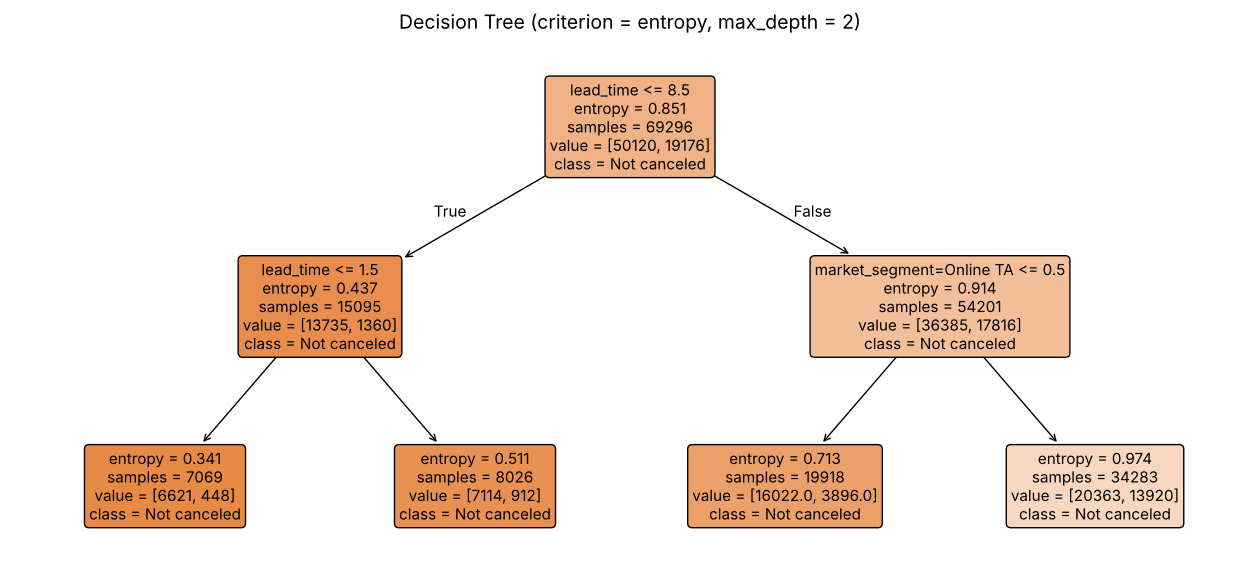

In [9]:
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(small_tree, feature_names=list(X_train.columns),
          class_names=["Not canceled", "Canceled"],
          filled=True, rounded=True, impurity=True, fontsize=11, ax=ax)
ax.set_title("Decision Tree (criterion = entropy, max_depth = 2)", fontsize=14)
fig.savefig(FIG_DIR / "clf_01_tree_plot_tree.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Growing the Tree One More Level (depth = 3)

The depth-2 tree was stopped early (**pre-pruning: stop growing the tree early**).
Because most training tuples are *Not canceled*, **majority voting** assigns
*Not canceled* to every depth-2 leaf. Growing one more level produces leaves whose majority is *Canceled*.

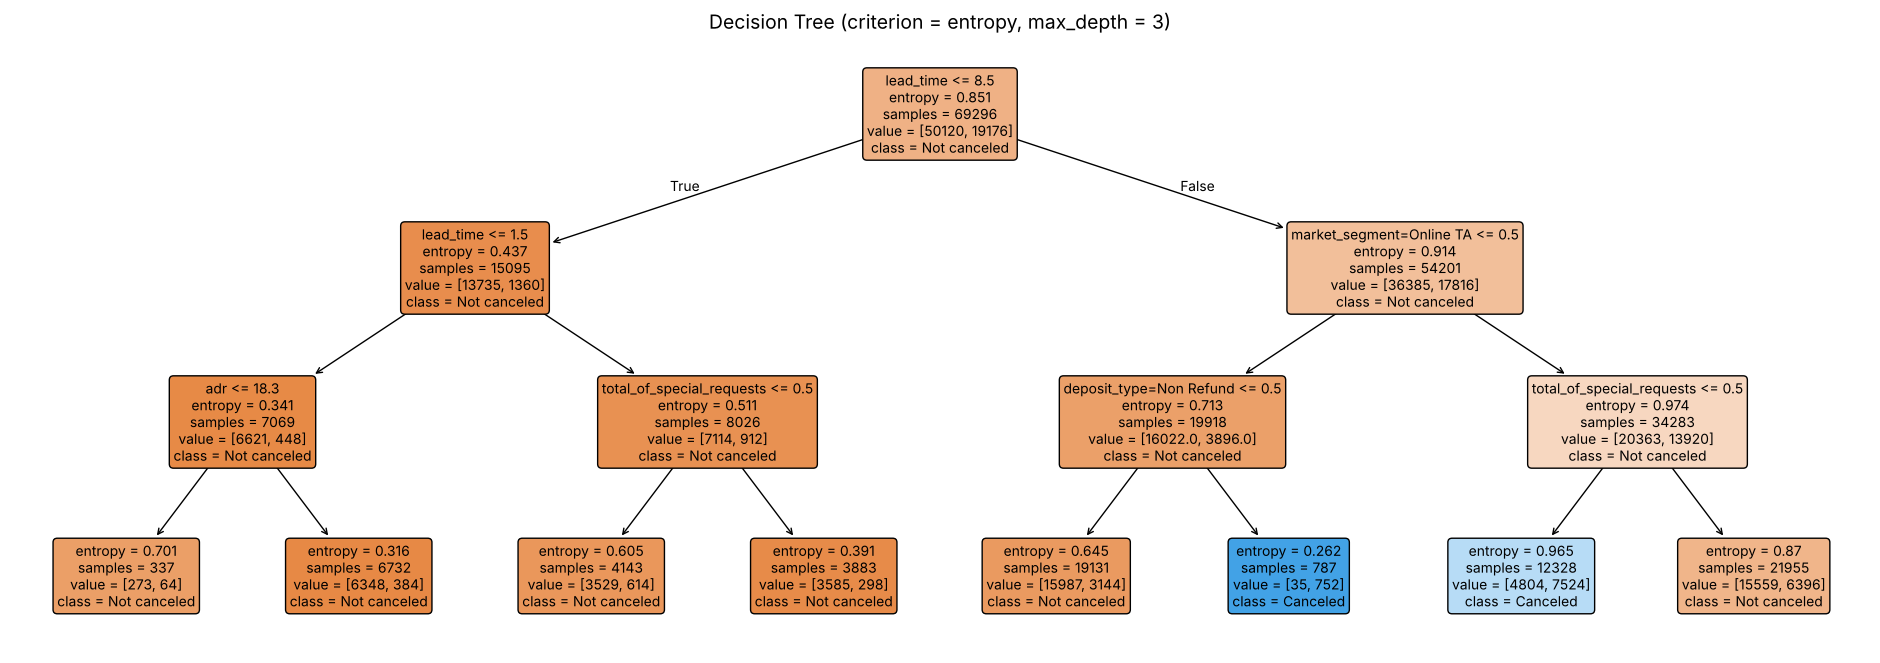

Test accuracy (depth 3): 0.775


In [10]:
tree_d3 = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
tree_d3.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(24, 8))
plot_tree(tree_d3, feature_names=list(X_train.columns),
          class_names=["Not canceled", "Canceled"],
          filled=True, rounded=True, impurity=True, fontsize=10, ax=ax)
ax.set_title("Decision Tree (criterion = entropy, max_depth = 3)", fontsize=14)
fig.savefig(FIG_DIR / "clf_02_tree_depth3.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Test accuracy (depth 3): {accuracy_score(y_test, tree_d3.predict(X_test)):.3f}")

## 5. Finding the Right Complexity: Cross-Validation

A model should learn patterns that help it predict **new records**; performing well on the
training data alone is not enough.

| Underfitting: too simple | Good fit: suitable complexity | Overfitting: too complex |
|---|---|---|
| Training and validation errors are both high | Validation error is near its lowest point | Training error remains low, but validation error rises |

**Cross-validation (k-fold, k = 10)**:
- Randomly partition the **training set** into k mutually exclusive subsets of approximately equal size
- At the i-th iteration, use $D_i$ as the validation set and the others as training set
- **Stratified cross-validation:** the class distribution in each fold is approximately the same as in the initial data

The **test set is not used here**, so it stays independent for the final accuracy estimate.
Model complexity is controlled by `max_depth` (**pre-pruning**).

$$Error\ rate = 1 - accuracy \quad$$

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate

folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rows = []
for d in range(1, 21):
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42)
    scores = cross_validate(model, X_train, y_train, cv=folds,
                            scoring="accuracy", return_train_score=True)
    rows.append({"max_depth": d,
                 "training error":   1 - scores["train_score"].mean(),
                 "validation error": 1 - scores["test_score"].mean()})

cv_table = pd.DataFrame(rows).set_index("max_depth")
cv_table.round(4)

,training error,validation error
max_depth,,
1,0.2767,0.2767
2,0.2767,0.2767
3,0.2271,0.2271
4,0.2161,0.2162
5,0.2117,0.2122
6,0.2096,0.2106
7,0.2069,0.2088
8,0.2040,0.2078
9,0.2016,0.2076


### 5.1 Training Error vs. Validation Error

Choose a model that performs well on unseen data — not simply the model with the lowest training error.

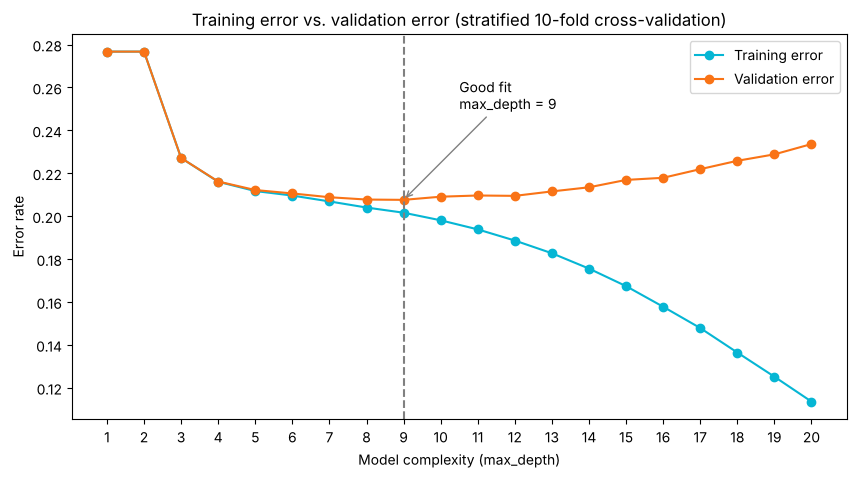

Selected max_depth = 9


In [12]:
best_depth = cv_table["validation error"].idxmin()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(cv_table.index, cv_table["training error"],   marker="o", color=CYAN,   label="Training error")
ax.plot(cv_table.index, cv_table["validation error"], marker="o", color=ORANGE, label="Validation error")
ax.axvline(best_depth, color="grey", ls="--")
ax.annotate(f"Good fit\nmax_depth = {best_depth}",
            xy=(best_depth, cv_table.loc[best_depth, "validation error"]),
            xytext=(best_depth + 1.5, 0.25), arrowprops=dict(arrowstyle="->", color="grey"))
ax.set_xlabel("Model complexity (max_depth)")
ax.set_ylabel("Error rate")
ax.set_title("Training error vs. validation error (stratified 10-fold cross-validation)")
ax.set_xticks(cv_table.index)
ax.legend()
fig.savefig(FIG_DIR / "clf_03_training_vs_validation_error.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Selected max_depth = {best_depth}")

### 5.2 Final Decision Tree

**Model construction** on the whole training set with the selected `max_depth`,
then **testing** once on the independent test set.

In [13]:
dt_model = DecisionTreeClassifier(criterion="entropy", max_depth=best_depth, random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print(f"max_depth = {best_depth} | leaves = {dt_model.get_n_leaves()}")
print(f"Training accuracy: {dt_model.score(X_train, y_train):.3f}")
print(f"Test accuracy:     {accuracy_score(y_test, y_pred_dt):.3f}")

max_depth = 9 | leaves = 288
Training accuracy: 0.798
Test accuracy:     0.792


## 6. Model Evaluation: Confusion Matrix

Each cell shows how many records from an actual class were assigned to a particular predicted class.
Positive class **C = Canceled**, negative class **¬C = Not canceled**.

| Actual \ Predicted | C | ¬C | |
|---|---|---|---|
| **C** | True Positives (TP) | False Negatives (FN) | P |
| **¬C** | False Positives (FP) | True Negatives (TN) | N |
| | P' | N' | All |

In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_dt, labels=[1, 0])
TP, FN, FP, TN = cm.ravel()

cm_table = pd.DataFrame(cm,
                        index=["Actual: Canceled (C)", "Actual: Not canceled (¬C)"],
                        columns=["Predicted: Canceled (C)", "Predicted: Not canceled (¬C)"])
cm_table["Total"] = cm_table.sum(axis=1)
cm_table.loc["Total"] = cm_table.sum()
cm_table

,Predicted: Canceled (C),Predicted: Not canceled (¬C),Total
Actual: Canceled (C),2139,2655,4794
Actual: Not canceled (¬C),950,11580,12530
Total,3089,14235,17324


### 6.1 Classifier Evaluation Metrics

- **Accuracy** = (TP + TN) / All
- **Error rate** = (FP + FN) / All
- **Sensitivity** (recall, true positive recognition rate) = TP / P
- **Specificity** (true negative recognition rate) = TN / N
- **Precision** (exactness) = TP / (TP + FP)
- **Recall** (completeness) = TP / (TP + FN)
- **F1-measure** (harmonic mean of precision and recall) = 2 × P × R / (P + R)

In [15]:
P, N, All = TP + FN, FP + TN, TP + FN + FP + TN

accuracy    = (TP + TN) / All
error_rate  = (FP + FN) / All
sensitivity = TP / P
specificity = TN / N
precision   = TP / (TP + FP)
recall      = TP / (TP + FN)
f1          = 2 * precision * recall / (precision + recall)

print(f"Accuracy    = ({TP:,} + {TN:,}) / {All:,} = {accuracy:.2%}")
print(f"Error rate  = ({FP:,} + {FN:,}) / {All:,} = {error_rate:.2%}")
print(f"Sensitivity = {TP:,} / {P:,} = {sensitivity:.2%}")
print(f"Specificity = {TN:,} / {N:,} = {specificity:.2%}")
print(f"Precision   = {TP:,} / ({TP:,} + {FP:,}) = {precision:.2%}")
print(f"Recall      = {TP:,} / ({TP:,} + {FN:,}) = {recall:.2%}")
print(f"F1          = 2 × {precision:.2%} × {recall:.2%} / ({precision:.2%} + {recall:.2%}) = {f1:.2%}")

Accuracy    = (2,139 + 11,580) / 17,324 = 79.19%
Error rate  = (950 + 2,655) / 17,324 = 20.81%
Sensitivity = 2,139 / 4,794 = 44.62%
Specificity = 11,580 / 12,530 = 92.42%
Precision   = 2,139 / (2,139 + 950) = 69.25%
Recall      = 2,139 / (2,139 + 2,655) = 44.62%
F1          = 2 × 69.25% × 44.62% / (69.25% + 44.62%) = 54.27%


### 6.2 ROC Curve and AUC

The ROC curve shows the trade-off between the **true positive rate (TP/P)** and the
**false positive rate (FP/N)** as the decision threshold varies.
The closer the AUC is to 0.5 (the diagonal), the less effective the model;
a model with perfect performance has an area of 1.0.

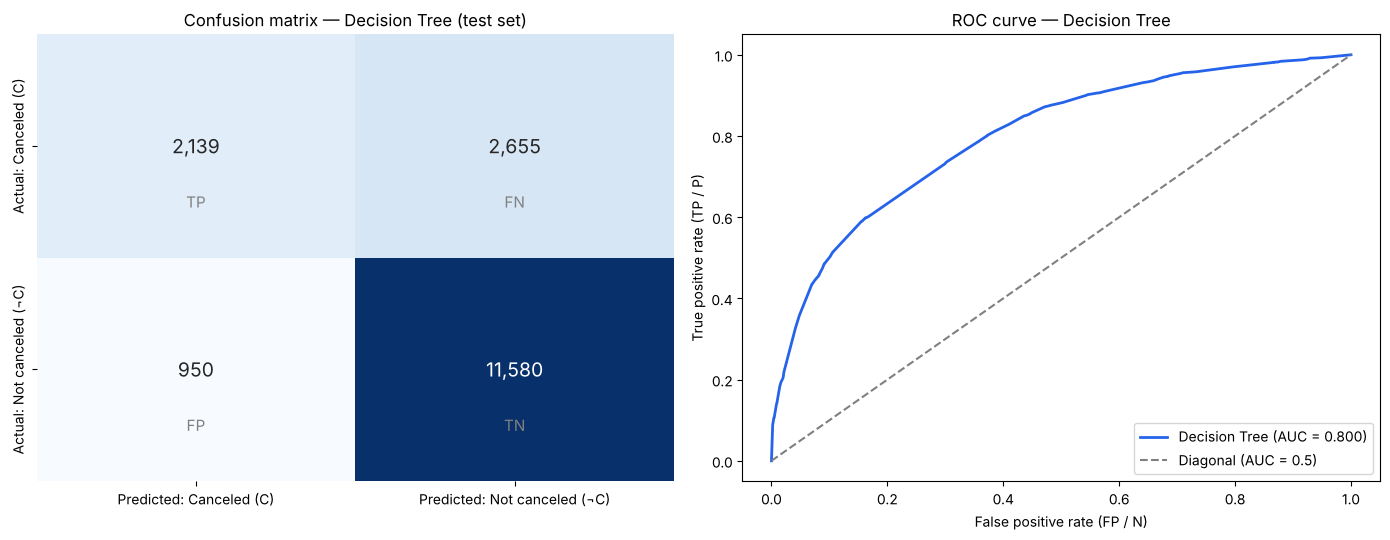

In [16]:
from sklearn.metrics import roc_curve, roc_auc_score

proba_dt = dt_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_dt)
auc_dt = roc_auc_score(y_test, proba_dt)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(cm_table.iloc[:2, :2], annot=True, fmt=",", cmap="Blues", cbar=False,
            ax=axes[0], annot_kws={"size": 14})
for i, row in enumerate([["TP", "FN"], ["FP", "TN"]]):
    for j, lab in enumerate(row):
        axes[0].text(j + 0.5, i + 0.75, lab, ha="center", va="center", fontsize=11, color="grey")
axes[0].set_title("Confusion matrix — Decision Tree (test set)")

axes[1].plot(fpr, tpr, color=BLUE, lw=2, label=f"Decision Tree (AUC = {auc_dt:.3f})")
axes[1].plot([0, 1], [0, 1], ls="--", color="grey", label="Diagonal (AUC = 0.5)")
axes[1].set_xlabel("False positive rate (FP / N)")
axes[1].set_ylabel("True positive rate (TP / P)")
axes[1].set_title("ROC curve — Decision Tree")
axes[1].legend(loc="lower right")

fig.tight_layout()
fig.savefig(FIG_DIR / "clf_04_dt_confusion_roc.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Naïve Bayes Classifier

**Bayes' theorem for classification**:

$$P(C|X) = \frac{P(X|C)\,P(C)}{P(X)}$$

- $P(C)$: prior probability of the class
- $P(X|C)$: likelihood of observing X if the class is C
- $P(C|X)$: posterior probability that X belongs to class C

$P(X)$ is the same for every class, so Naïve Bayes compares only:

$$Score(C) = P(C)\prod_{i=1}^{n} P(x_i|C)$$

and selects the class with the **highest score**.

### 7.1 Prepare the attributes

Naïve Bayes counts attribute values in frequency tables, so every attribute is treated as categorical.
The two continuous attributes `lead_time` and `adr` are discretized into intervals (Method 1).

In [17]:
# Treat every attribute value as a category
nb_data = df[NUMERIC + CATEGORICAL].astype(str)

# Discretize the two continuous attributes
nb_data["lead_time"] = pd.cut(df["lead_time"], [-1, 7, 30, 90, 180, 365, np.inf],
                              labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"]).astype(str)
nb_data["adr"] = pd.cut(df["adr"], [-np.inf, 70, 100, 130, 160, np.inf],
                        labels=["<=70", "70-100", "100-130", "130-160", ">160"]).astype(str)

# Same training and test tuples as the decision tree
nb_train = nb_data.loc[X_train.index]
nb_test = nb_data.loc[X_test.index]
nb_train.head(3)

,lead_time,arrival_month_num,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,total_of_special_requests,has_agent,has_company,hotel,meal,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type
22898,181-365,9,38,15,0,3,2,0,0,0,...,0,0,1,Resort Hotel,BB,Groups,Direct,A,No Deposit,Transient-Party
14147,31-90,11,45,7,2,6,2,0,0,0,...,3,1,0,Resort Hotel,BB,Online TA,TA/TO,D,No Deposit,Transient-Party
48149,31-90,4,17,24,1,2,1,0,0,0,...,0,0,0,City Hotel,BB,Direct,Direct,D,No Deposit,Transient


### 7.2 Prior probability and likelihood table

In [18]:
# Prior probability of each class
prior = y_train.value_counts(normalize=True)
print("P(Canceled)     =", round(prior[1], 4))
print("P(Not canceled) =", round(prior[0], 4))

P(Canceled)     = 0.2767
P(Not canceled) = 0.7233


In [19]:
# Frequency table -> likelihood table for one attribute
freq = pd.crosstab(nb_train["deposit_type"], y_train)
print(freq, "\n")
print((freq / freq.sum()).round(4))

is_canceled       0      1
deposit_type              
No Deposit    50007  18371
Non Refund       48    785
Refundable       65     20 

is_canceled        0       1
deposit_type                
No Deposit    0.9977  0.9580
Non Refund    0.0010  0.0409
Refundable    0.0013  0.0010


### 7.3 Classify one new booking by hand

Multiply the prior by the likelihood of each clue, then select the class with the higher score.
The scores can be normalised so that they add up to 1.

In [20]:
# First booking in the test set
x_new = nb_test.iloc[0]

score = {1: prior[1], 0: prior[0]}
for attr, value in x_new.items():
    freq = pd.crosstab(nb_train[attr], y_train)
    likelihood = freq / freq.sum()
    score[1] *= likelihood.loc[value, 1]      # P(x_i | Canceled)
    score[0] *= likelihood.loc[value, 0]      # P(x_i | Not canceled)

print("Score(Canceled)     =", score[1])
print("Score(Not canceled) =", score[0])
print("P(Canceled | X)     =", round(score[1] / (score[1] + score[0]), 4))
print("Actual class        =", y_test.iloc[0])

Score(Canceled)     = 7.949042261304797e-17
Score(Not canceled) = 6.982426647025659e-16
P(Canceled | X)     = 0.1022
Actual class        = 0


### 7.4 Zero-probability problem: Laplacian correction

If a value never appears with a class, its probability is 0 and the whole score becomes 0.
The Laplacian correction adds 1 to each case.

In [21]:
freq = pd.crosstab(nb_train["market_segment"], y_train)
print(freq)

count = freq.loc["Undefined", 0]          # Undefined never appears with Not canceled
n_not_canceled = freq[0].sum()
n_values = len(freq)

print("\nWithout correction:", count / n_not_canceled)
print("With correction:   ", (count + 1) / (n_not_canceled + n_values))

is_canceled         0      1
market_segment              
Aviation          136     35
Complementary     460     69
Corporate        2960    406
Direct           7980   1377
Groups           2795   1064
Offline TA/TO    9341   1673
Online TA       26448  14550
Undefined           0      2

Without correction: 0.0
With correction:    1.994893073731248e-05


### 7.5 Train and test the Naïve Bayes classifier

`CategoricalNB(alpha=1)` applies the same calculation to all bookings, with the Laplacian correction (add 1).

In [22]:
from sklearn.naive_bayes import CategoricalNB

# Give each attribute value an integer code
nb_codes = nb_data.apply(lambda col: col.astype("category").cat.codes)

nb_model = CategoricalNB(alpha=1, min_categories=nb_data.nunique().values)
nb_model.fit(nb_codes.loc[X_train.index], y_train)

y_pred_nb = nb_model.predict(nb_codes.loc[X_test.index])
print("P(Canceled | X) for the first test booking:", round(nb_model.predict_proba(nb_codes.loc[X_test.index])[0, 1], 4))
print("Test accuracy:", round(accuracy_score(y_test, y_pred_nb), 4))

P(Canceled | X) for the first test booking: 0.1017


Test accuracy: 0.7229


### 7.6 Evaluation

The same formulas as the decision tree, written once so every classifier is evaluated the same way.

In [23]:
def evaluate(y_true, y_pred):
    TP, FN, FP, TN = confusion_matrix(y_true, y_pred, labels=[1, 0]).ravel()
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    return {"TP": TP, "FN": FN, "FP": FP, "TN": TN,
            "Accuracy": (TP + TN) / (TP + FN + FP + TN),
            "Error rate": (FP + FN) / (TP + FN + FP + TN),
            "Sensitivity": TP / (TP + FN),
            "Specificity": TN / (FP + TN),
            "Precision": precision,
            "Recall": recall,
            "F1": 2 * precision * recall / (precision + recall)}

results = pd.DataFrame({"Decision Tree": evaluate(y_test, y_pred_dt),
                        "Naive Bayes": evaluate(y_test, y_pred_nb)})
results.round(4)

,Decision Tree,Naive Bayes
TP,2139.0000,2802.0000
FN,2655.0000,1992.0000
FP,950.0000,2808.0000
TN,11580.0000,9722.0000
Accuracy,0.7919,0.7229
Error rate,0.2081,0.2771
Sensitivity,0.4462,0.5845
Specificity,0.9242,0.7759
Precision,0.6925,0.4995
Recall,0.4462,0.5845


## 8. k-Nearest Neighbor (k-NN)

k-NN is a **lazy learner**: it stores the training records and does most of the work when a new record must be predicted.

For a new record:
1. Choose the number of neighbours, k
2. Calculate its distance from every training record
3. Select the k closest records
4. **Classification:** choose the most common class among the neighbours

**Euclidean distance:**

$$d(x, q) = \sqrt{(x_1 - q_1)^2 + (x_2 - q_2)^2 + \dots + (x_n - q_n)^2}$$

### 8.1 Normalise the attributes

Features should be normalised before calculating distance; otherwise an attribute with large values
(e.g. `lead_time` up to 709) may dominate an attribute measured from 0 to 1.
The scaler is fitted on the training set only.

In [24]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before:", X_train["lead_time"].min(), "-", X_train["lead_time"].max())
print("After: ", X_train_scaled[:, 0].min(), "-", X_train_scaled[:, 0].max())

Before: 0 - 709
After:  0.0 - 1.0


### 8.2 Find the nearest records by hand

In [25]:
# First booking in the test set
q = X_test_scaled[0]

# Euclidean distance from q to every training record
distances = np.sqrt(((X_train_scaled - q) ** 2).sum(axis=1))

# The 5 closest training records
nearest = np.argsort(distances)[:5]
print("Distances:", distances[nearest].round(4))
print("Classes:  ", y_train.iloc[nearest].values)
print("Prediction (majority of 5):", y_train.iloc[nearest].mode()[0], "| Actual:", y_test.iloc[0])

Distances: [0.1872 0.2186 0.2374 0.2958 0.2968]
Classes:   [1 0 0 0 1]
Prediction (majority of 5): 0 | Actual: 0


### 8.3 Selection of k

- **Small k:** affected by noise, may overfit (complex decision boundary)
- **Large k:** may ignore local patterns, may underfit (smoother boundary)

Test several values of k using **validation data** and select the value with the best validation performance.
For binary classification, an **odd k** reduces ties.

In [26]:
# Split the training set into training and validation data
X_tr, X_val, y_tr, y_val = train_test_split(X_train_scaled, y_train, test_size=0.2,
                                            stratify=y_train, random_state=42)

neighbors = np.arange(1, 42, 2)          # odd values of k
train_accuracies = {}
val_accuracies = {}

for k in neighbors:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_tr, y_tr)
    train_accuracies[k] = knn.score(X_tr, y_tr)
    val_accuracies[k] = knn.score(X_val, y_val)

best_k = max(val_accuracies, key=val_accuracies.get)
print("Best k:", best_k, "| Validation accuracy:", round(val_accuracies[best_k], 4))

Best k: 31 | Validation accuracy: 0.7719


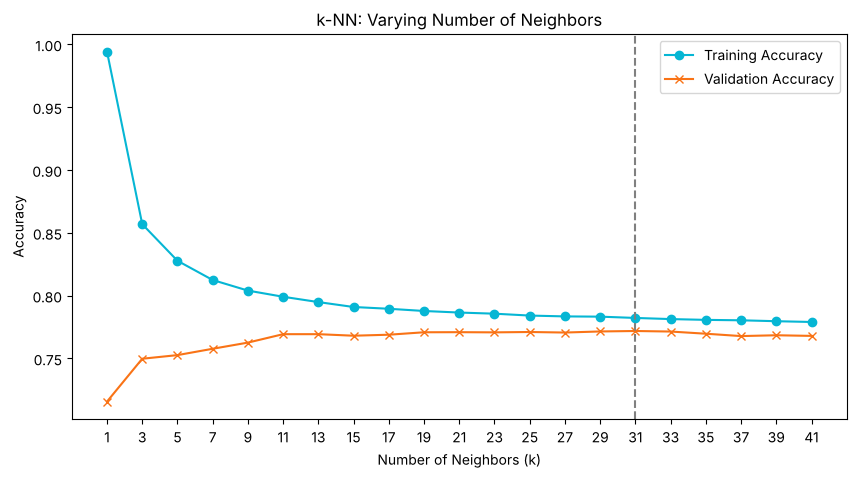

In [27]:
plt.figure(figsize=(10, 5))
plt.title("k-NN: Varying Number of Neighbors")
plt.plot(neighbors, train_accuracies.values(), label="Training Accuracy", marker="o", color=CYAN)
plt.plot(neighbors, val_accuracies.values(), label="Validation Accuracy", marker="x", color=ORANGE)
plt.axvline(best_k, color="grey", ls="--")
plt.xticks(neighbors)
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.legend()
plt.savefig(FIG_DIR / "clf_05_knn_k.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.4 Train and test the final k-NN

In [28]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
print("Test accuracy:", round(accuracy_score(y_test, y_pred_knn), 4))

Test accuracy: 0.773


In [29]:
results["k-NN"] = pd.Series(evaluate(y_test, y_pred_knn))
results.round(4)

,Decision Tree,Naive Bayes,k-NN
TP,2139.0000,2802.0000,1792.0000
FN,2655.0000,1992.0000,3002.0000
FP,950.0000,2808.0000,930.0000
TN,11580.0000,9722.0000,11600.0000
Accuracy,0.7919,0.7229,0.7730
Error rate,0.2081,0.2771,0.2270
Sensitivity,0.4462,0.5845,0.3738
Specificity,0.9242,0.7759,0.9258
Precision,0.6925,0.4995,0.6583
Recall,0.4462,0.5845,0.3738


## 9. Logistic Regression

Logistic regression is a **classification** method. It predicts in two stages:
1. Calculate a score with a linear equation: $z = b + w_1x_1 + w_2x_2 + \dots + w_nx_n$
2. Convert the score into a probability between 0 and 1 with the **sigmoid function**

The class is then chosen with a **decision threshold** of 0.5 (probability ≥ 0.5 → Canceled).
The normalised attributes from the k-NN section are used.

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Initialize and train the Logistic Regression model
lr_base = LogisticRegression(max_iter=1000)
lr_base.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred_lr_base = lr_base.predict(X_test_scaled)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_base, labels=[1, 0]))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_base))

Confusion Matrix:
[[ 1515  3279]
 [  681 11849]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.95      0.86     12530
           1       0.69      0.32      0.43      4794

    accuracy                           0.77     17324
   macro avg       0.74      0.63      0.65     17324
weighted avg       0.76      0.77      0.74     17324



### 9.1 Performance enhancement: tuning with GridSearchCV

- **C:** regularization strength (smaller C = stronger regularization)
- **penalty:** regularization type, `l1` or `l2`

GridSearchCV tries every combination with 5-fold cross-validation on the training set and keeps the best one.

In [31]:
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings("ignore")   # hide version warnings about the penalty parameter

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"]
}

grid_lr = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_lr.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_lr.best_score_, 4))

Best Parameters: {'C': 100, 'penalty': 'l1', 'solver': 'liblinear'}
Best Cross-Validation Accuracy: 0.777


In [32]:
lr_model = grid_lr.best_estimator_
y_pred_lr = lr_model.predict(X_test_scaled)

print("Test accuracy before tuning:", round(accuracy_score(y_test, y_pred_lr_base), 4))
print("Test accuracy after tuning: ", round(accuracy_score(y_test, y_pred_lr), 4))
print("\nConfusion Matrix after tuning:")
print(confusion_matrix(y_test, y_pred_lr, labels=[1, 0]))

Test accuracy before tuning: 0.7714
Test accuracy after tuning:  0.7781

Confusion Matrix after tuning:
[[ 1622  3172]
 [  673 11857]]


## 10. Random Forest

A random forest builds **many decision trees**, each on a random sample of the training records and
a random subset of the attributes. The final class is chosen by **majority voting** of the trees.

In [33]:
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)

print("Training accuracy:", round(rf_base.score(X_train, y_train), 4))
print("Test accuracy:    ", round(rf_base.score(X_test, y_test), 4))

Training accuracy: 0.9942


Test accuracy:     0.8047


Without limits, every tree grows until its leaves are pure, so the training accuracy is almost 100%
while the test accuracy is much lower — the forest **overfits**.

### 10.1 Performance enhancement: tuning with GridSearchCV

- **n_estimators:** number of trees
- **max_depth:** maximum depth of each tree (pre-pruning)

In [34]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, 30]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), param_grid, cv=5, scoring="accuracy")
grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_rf.best_score_, 4))

Best Parameters: {'max_depth': 30, 'n_estimators': 200}
Best Cross-Validation Accuracy: 0.8053


In [35]:
rf_model = grid_rf.best_estimator_
y_pred_rf = rf_model.predict(X_test)

print("Training accuracy:", round(rf_model.score(X_train, y_train), 4))
print("Test accuracy:    ", round(accuracy_score(y_test, y_pred_rf), 4))

Training accuracy: 0.9814
Test accuracy:     0.8073


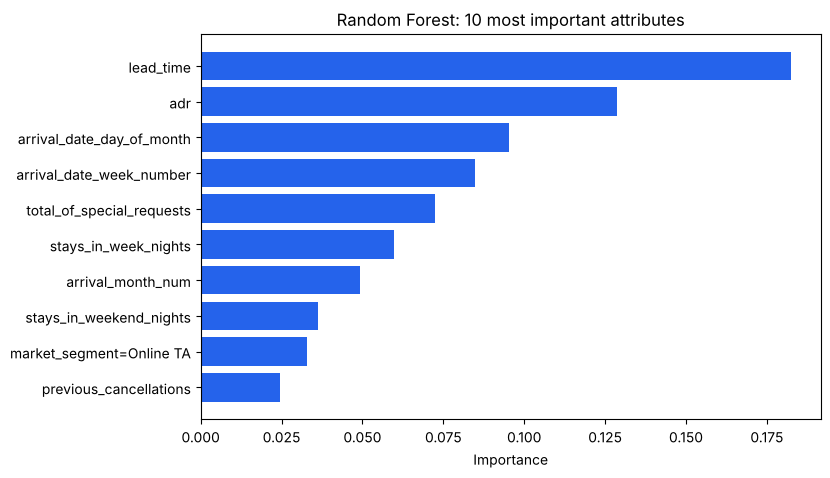

In [36]:
importance = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.barh(importance.index[::-1], importance.values[::-1], color=BLUE)
plt.xlabel("Importance")
plt.title("Random Forest: 10 most important attributes")
plt.savefig(FIG_DIR / "clf_06_rf_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Model Performance Comparison

All five classifiers use the **same training and test sets** and the same evaluation measures.

In [37]:
results["Logistic Regression"] = pd.Series(evaluate(y_test, y_pred_lr))
results["Random Forest"] = pd.Series(evaluate(y_test, y_pred_rf))

probas = {"Decision Tree": proba_dt,
          "Naive Bayes": nb_model.predict_proba(nb_codes.loc[X_test.index])[:, 1],
          "k-NN": knn_model.predict_proba(X_test_scaled)[:, 1],
          "Logistic Regression": lr_model.predict_proba(X_test_scaled)[:, 1],
          "Random Forest": rf_model.predict_proba(X_test)[:, 1]}

results.loc["AUC"] = [roc_auc_score(y_test, probas[m]) for m in results.columns]
results.round(4)

,Decision Tree,Naive Bayes,k-NN,Logistic Regression,Random Forest
TP,2139.0000,2802.0000,1792.0000,1622.0000,2462.0000
FN,2655.0000,1992.0000,3002.0000,3172.0000,2332.0000
FP,950.0000,2808.0000,930.0000,673.0000,1006.0000
TN,11580.0000,9722.0000,11600.0000,11857.0000,11524.0000
Accuracy,0.7919,0.7229,0.7730,0.7781,0.8073
Error rate,0.2081,0.2771,0.2270,0.2219,0.1927
Sensitivity,0.4462,0.5845,0.3738,0.3383,0.5136
Specificity,0.9242,0.7759,0.9258,0.9463,0.9197
Precision,0.6925,0.4995,0.6583,0.7068,0.7099
Recall,0.4462,0.5845,0.3738,0.3383,0.5136


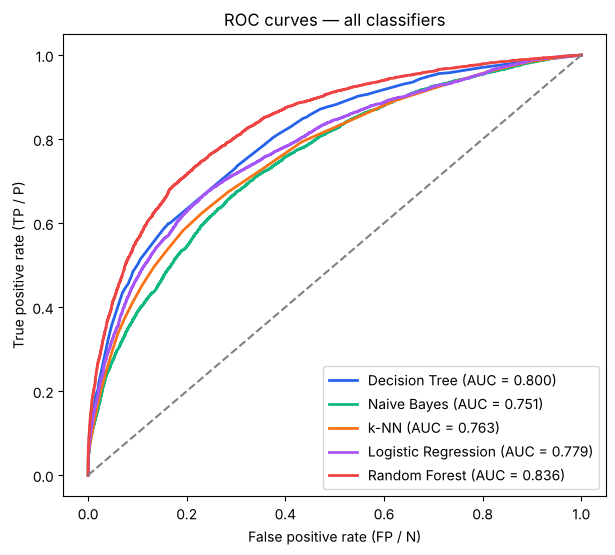

In [38]:
colors = {"Decision Tree": BLUE, "Naive Bayes": GREEN, "k-NN": ORANGE,
          "Logistic Regression": "#a855f7", "Random Forest": "#ef4444"}

plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, color=colors[name], label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], ls="--", color="grey")
plt.xlabel("False positive rate (FP / N)")
plt.ylabel("True positive rate (TP / P)")
plt.title("ROC curves — all classifiers")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "clf_07_roc_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Summary

**Problem:** Can a hotel booking be classified as *Canceled* or *Not canceled* using only attributes known at booking time?

| | Decision Tree | Naive Bayes | k-NN | Logistic Regression | Random Forest |
|---|---|---|---|---|---|
| Tuning | max_depth = 9 (10-fold CV) | Laplacian correction | k = 31 (validation data) | C = 100, L1 (GridSearchCV) | 200 trees, max_depth = 30 (GridSearchCV) |
| Accuracy | 79.2% | 72.3% | 77.3% | 77.8% | **80.7%** |
| Precision | 69.3% | 50.0% | 65.8% | 70.7% | **71.0%** |
| Recall | 44.6% | **58.5%** | 37.4% | 33.8% | 51.4% |
| F1 | 54.3% | 53.9% | 47.7% | 45.8% | **59.6%** |
| AUC | 0.800 | 0.751 | 0.763 | 0.779 | **0.837** |

**Findings**
1. **Random Forest** gives the best accuracy, F1 and AUC. Combining many trees by majority voting is more accurate than one tree.
2. The **Decision Tree** is second and is the easiest model to explain (white box).
3. **Logistic Regression** improved from 77.1% to 77.8% after tuning, but it finds only 34% of the cancellations: the relation between the attributes and cancellation is not linear.
4. **Naive Bayes** has the highest recall but the lowest precision (many false alarms).
5. The most important attribute is **lead_time**: bookings made 8 days or less before arrival are rarely canceled (9.0%) compared with 32.9% for the rest; `deposit_type = Non Refund`, `market_segment = Online TA` and `total_of_special_requests` are also important.

**Limitation:** all models recognise about half or fewer of the canceled bookings, because the classes are imbalanced (72% / 28%).